**LSTM-based Time-Series Model**

Predict future sensor readings in patients with parkinsons disease

In [ ]:

import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Bidirectional , BatchNormalization
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
import matplotlib.pyplot as plt

#warning ignotr
import warnings
warnings.filterwarnings("ignore")


**Start with a random seed**

In [ ]:
def set_random_seed(seed=42):

  # 1.set the python-built-in pseudo-random generator at a fixed value
  random.seed(seed)

  # 2. set the numpy pseudo-random generator at a fixed value
  np.random.seed(seed)

  #3. set the tensorflow pseudo-random generator at a fixed value
  tf.random.set_seed(seed)

  #Configure new global session for tensorflow(if using TF 1.x or legacy backends , otherwise tf.random.set_seed is enough )
  print(f"Global seed set to {seed}. Results should be now Reproducible")



In [ ]:
#load Dataset

df = pd.read_csv("Clean_Dataset.csv")

df.head(5)


,Time,Accel_X,Accel_Y,Accel_Z,Gyro_X,Gyro_Y,Gyro_Z,Patient_id,Task,Device location,Height,Weight,Gender,Condition,Age_At_Diagnosis,Handedness,Normalized_Time
0,0.009805,0.002275,0.013380,0.005852,-0.014924,-0.025833,0.004746,1,CrossArms,LeftWrist,173,78,0,0,56,0,0.000393
1,0.019807,0.001332,0.016225,0.005543,-0.009529,-0.033264,0.005853,1,CrossArms,LeftWrist,173,78,0,0,56,0,0.055648
2,0.029791,0.001354,0.018107,0.007207,-0.007440,-0.029995,0.009008,1,CrossArms,LeftWrist,173,78,0,0,56,0,0.110804
3,0.039801,0.001441,0.016004,0.004999,-0.011757,-0.027815,0.017495,1,CrossArms,LeftWrist,173,78,0,0,56,0,0.166104
4,0.052410,0.000535,0.015800,0.005716,-0.013891,-0.029924,0.022822,1,CrossArms,LeftWrist,173,78,0,0,56,0,0.235761


**Encode categorical variables**

In [ ]:
label_encoders = {}
for col in ["Task"]:
  label_encoders[col] = LabelEncoder()
  df[col] = label_encoders[col].fit_transform(df[col])

#map device location to numerical values
df["Device location"] = df["Device location"].map({"RightWrist":0, "LeftWrist":1})

**Define Input and Target Values**

In [ ]:
#Define Input features (past movements plus metadata) and target (fututre movements)

features = ['Accel_X', 'Accel_Y', 'Accel_Z', 'Gyro_X', 'Gyro_Y', 'Gyro_Z', 'Time', 'Condition']
target = ['Accel_X', 'Accel_Y', 'Accel_Z', 'Gyro_X', 'Gyro_Y', 'Gyro_Z'] # Predict future movement

Scale Features and Segment Data

In [ ]:
#sort data by patient_id and time
df = df.sort_values(by=["Patient_id"])

#initialize list to store segmented data
train_data_list = []
test_data_list = []

#split and normlaize per patient to prevent data leakage
scaler= MinMaxScaler()

for patient_id , patient_df in df.groupby("Patient_id"):
  split_index = round(int(len(patient_df)*0.8))  #80% train , 20% test

  train_patient = patient_df.iloc[:split_index]
  test_patient = patient_df.iloc[split_index:]

  #Normlaize per patient
  train_patient[features] = scaler.fit_transform(train_patient[features])
  test_patient[features] = scaler.transform(test_patient[features])

  train_data_list.append(train_patient)
  test_data_list.append(test_patient)


#Combine segmented data
train_data = pd.concat(train_data_list)
test_data = pd.concat(test_data_list)









**Create Data Sequence**

In [ ]:
#function to create sequence for each patients data
sequence_length = 10
def create_sequences(data, sequence_length=sequence_length):
  sequences=[]
  labels = []

  for patient_id, patient_df in data.groupby('Patient_id'):
    patient_data = patient_df.reset_index(drop=True)  #reset index for sequential slicing

    for i in range(len(patient_data)-sequence_length):
      seq = patient_data.iloc[i:i+sequence_length][features].values
      label = patient_data.iloc[i:i+sequence_length][target].values #predict next step
      sequences.append(seq)
      labels.append(label)

  return np.array(sequences), np.array(labels)



#create sequences
x_train , y_train = create_sequences(train_data,sequence_length=sequence_length)
x_test , y_test = create_sequences(test_data,sequence_length=sequence_length)






**Define LSTM Model**

In [ ]:
from tensorflow.keras import regularizers



#Define LSTM Model

model = Sequential([
    Bidirectional(LSTM(64,return_sequences=True,input_shape = (sequence_length,len(features)),)),
    BatchNormalization(),
    Dropout(0.5),

    LSTM(32,return_sequences=True),
    BatchNormalization(),
    Dropout(0.5),

    LSTM(16,return_sequences=False),
    BatchNormalization(),
    Dropout(0.5),

    Dense(64, activation='relu'),
    BatchNormalization(),
    Dropout(0.5),

    Dense(32, activation='relu'),
    Dropout(0.5),

    Dense(len(target), activation='linear')   # Predict movement values


])

In [ ]:
#Compile model

optimizer = tf.keras.optimizers.Adam(learning_rate=0.0001, clipnorm=1.0)
model.compile(loss='mse',optimizer=optimizer,metrics=['mae'])

#Train model
history = model.fit(x_train,y_train, epochs=30, batch_size=16,validation_data=(x_test,y_test))



Epoch 1/30
6528/6528 ━━━━━━━━━━━━━━━━━━━━ 118s 17ms/step - loss: 0.4803 - mae: 0.4164 - val_loss: 0.0786 - val_mae: 0.2341
Epoch 2/30
6528/6528 ━━━━━━━━━━━━━━━━━━━━ 140s 16ms/step - loss: 0.0392 - mae: 0.1571 - val_loss: 0.0514 - val_mae: 0.1874
Epoch 3/30
6528/6528 ━━━━━━━━━━━━━━━━━━━━ 143s 17ms/step - loss: 0.0311 - mae: 0.1392 - val_loss: 0.0436 - val_mae: 0.1693
Epoch 4/30
6528/6528 ━━━━━━━━━━━━━━━━━━━━ 107s 16ms/step - loss: 0.0287 - mae: 0.1332 - val_loss: 0.0400 - val_mae: 0.1604
Epoch 5/30
6528/6528 ━━━━━━━━━━━━━━━━━━━━ 146s 17ms/step - loss: 0.0276 - mae: 0.1303 - val_loss: 0.0375 - val_mae: 0.1545
Epoch 6/30
6528/6528 ━━━━━━━━━━━━━━━━━━━━ 140s 17ms/step - loss: 0.0268 - mae: 0.1281 - val_loss: 0.0360 - val_mae: 0.1501
Epoch 7/30
6528/6528 ━━━━━━━━━━━━━━━━━━━━ 107s 16ms/step - loss: 0.0263 - mae: 0.1265 - val_loss: 0.0351 - val_mae: 0.1477
Epoch 8/30
6528/6528 ━━━━━━━━━━━━━━━━━━━━ 108s 17ms/step - loss: 0.0258 - mae: 0.1250 - val_loss: 0.0344 - val_mae: 0.1462
Epoch 9/30
6528/

**Evaluate Model**

In [ ]:
#Evaluate model

loss, mae = model.evaluate(x_test, y_test)
print(f"Test MAE: {mae:.2f}")
print(f"Test Loss: {loss:.2f}")

738/738 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - loss: 0.0334 - mae: 0.1434
Test MAE: 0.14
Test Loss: 0.03


**Visualize Result**

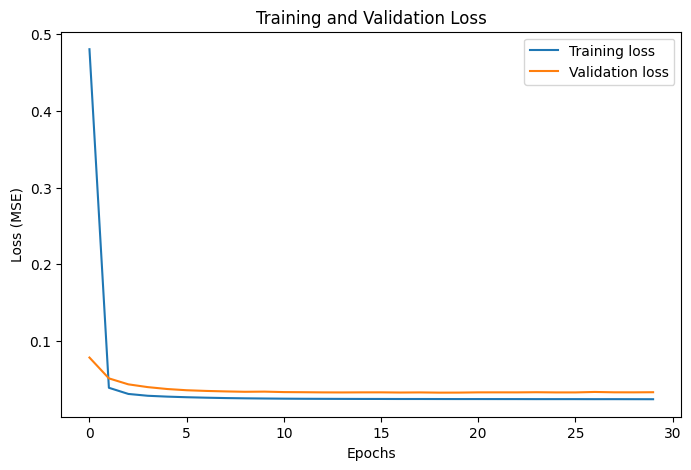

In [ ]:
#Visualize the model
#plot training and validation loss

plt.figure(figsize=(8,5))
plt.plot(history.history['loss'],label='Training loss')
plt.plot(history.history['val_loss'],label='Validation loss')
plt.xlabel('Epochs')
plt.ylabel('Loss (MSE)')
plt.title('Training and Validation Loss')
plt.legend()
plt.show();

**Save prediction for Visualization**

In [ ]:
#predict movement varaibility progression
y_pred = model.predict(x_test)

 # Convert X_test to a DataFrame for comparison
x_test_df = pd.DataFrame(x_test[:,-1,:],columns=[f'{col}'for col in features])
x_test_df.reset_index(drop=True, inplace=True)

#convert the predicition into dataframe
y_pred_df = pd.DataFrame(y_pred, columns=[f'Predicted_{col}' for col in target])

#Combine the input data with predictions
comparison_df = pd.concat([x_test_df,y_pred_df],axis=1)

#sort by time
comparison_df = comparison_df.sort_values(by=['Time'])

#save the updatred dataset with input vs predicted data
#comparison_df.to_csv('/content/drive/MyDrive/Parkinson_prediction/movement_variability_pred.csv')

print("Comparison dataset saved successfully.")


738/738 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step


ValueError: Must pass 2-d input. shape=(23616, 10, 6)